# The Hidden Layer: test cases 2 and 3

**IITGN PG Diploma · Business Analytics**

This notebook covers the Python steps of Test Case 2 (the routing AI at Kalpa Retail) and Test Case 3 (expense claims at Kalpa Financial Services). Test Case 1 is solved on paper.

Work top to bottom. Each task cell says what to compute. Write your answers to the written questions in your handout, not here.

Libraries: NumPy, pandas, SciPy and matplotlib only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare

---
## Test Case 2: The routing AI at Kalpa Retail

Model of the network:
- 60 dark stores.
- Each store has a **true** on-time rate drawn from N(80, 5). It never changes.
- Each quarter adds fresh **noise** drawn from N(0, 5).
- The observed rate is true rate plus noise. With these settings the quarter-to-quarter correlation is 0.5.

No store receives any tool in the simulation unless a task says so.

### Task 3. How much do the worst 12 stores improve with no tool?

Simulate one network, select the bottom 12 stores by Q1, and record their average Q2 minus their average Q1. Repeat 5,000 times.

Report the average improvement, its standard deviation, and the share of runs with an improvement of at least 6 points.

In [2]:
rng = np.random.default_rng(42)
runs = 5000
gains = []

for r in range(runs):
    true = rng.normal(80, 5, 60)          # each store's true rate, fixed
    q1 = true + rng.normal(0, 5, 60)      # Q1 observed: true rate plus noise
    q2 = true + rng.normal(0, 5, 60)      # Q2 observed: fresh noise, no tool
    worst = np.argsort(q1)[:12]           # the 12 lowest stores in Q1
    gains.append(q2[worst].mean() - q1[worst].mean())

gains = np.array(gains)
print("Average improvement:", round(gains.mean(), 2))
print("Standard deviation: ", round(gains.std(), 2))
print("Share of runs with 6 points or more:", round((gains >= 6).mean(), 3))

Average improvement: 4.89
Standard deviation:  1.89
Share of runs with 6 points or more: 0.276


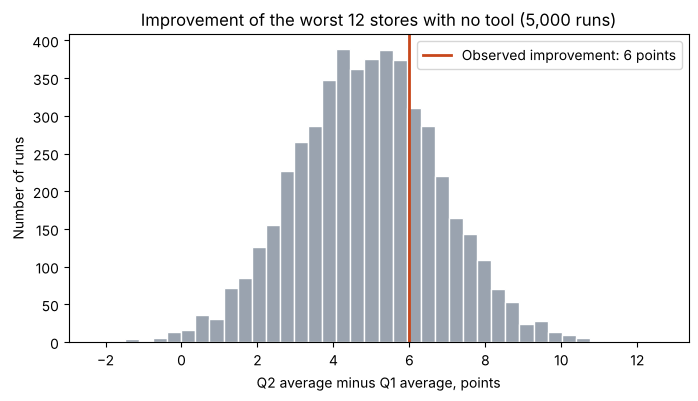

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(gains, bins=40, color="#9AA3AF", edgecolor="white")
plt.axvline(6, color="#C8471C", linewidth=2, label="Observed improvement: 6 points")
plt.title("Improvement of the worst 12 stores with no tool (5,000 runs)")
plt.xlabel("Q2 average minus Q1 average, points")
plt.ylabel("Number of runs")
plt.legend()
plt.show()

### Task 4. Hotelling's reversal

Simulate **one** network. Group the stores into quarters by **Q2**, then compare each group's Q1 and Q2 averages.

What would Hotelling conclude from this table?

In [4]:
rng = np.random.default_rng(7)
true = rng.normal(80, 5, 60)
q1 = true + rng.normal(0, 5, 60)
q2 = true + rng.normal(0, 5, 60)

stores = pd.DataFrame({"q1": q1, "q2": q2})
stores["group_by_q2"] = pd.qcut(stores["q2"], 4, labels=["Bottom", "Q2", "Q3", "Top"])
stores.groupby("group_by_q2", observed=True)[["q1", "q2"]].mean().round(1)

,q1,q2
group_by_q2,,
Bottom,75.1,70.5
Q2,76.6,75.7
Q3,79.8,79.0
Top,82.7,85.8


### Task 6. A fair test of the tool

Take the bottom 24 stores by Q1. Randomly assign 12 to the tool and 12 to no tool. Give the tool a **true effect of +1 point** in Q2. The estimate is the treated Q2 average minus the control Q2 average.

Repeat 5,000 times and report the mean and standard deviation of the estimate.

In [5]:
rng = np.random.default_rng(42)
estimates = []

for r in range(5000):
    true = rng.normal(80, 5, 60)
    q1 = true + rng.normal(0, 5, 60)
    q2 = true + rng.normal(0, 5, 60)
    bottom24 = np.argsort(q1)[:24]                 # candidates, chosen by Q1
    treated = rng.permutation(bottom24)[:12]       # random half get the tool
    control = np.setdiff1d(bottom24, treated)      # the other half do not
    q2[treated] = q2[treated] + 1.0                # the tool's true effect
    estimates.append(q2[treated].mean() - q2[control].mean())

estimates = np.array(estimates)
print("Mean estimate:      ", round(estimates.mean(), 2))
print("Standard deviation: ", round(estimates.std(), 2))

Mean estimate:       0.97
Standard deviation:  2.63


---
## Test Case 3: Before the AI approves expense claims

Upload `claims.csv` to this notebook's files (in Colab, use the folder icon on the left), then run the next cell.

Columns: `claim_id`, `employee_id`, `category`, `amount` (rupees).

In [6]:
claims = pd.read_csv("claims.csv")
print(claims.shape)
claims.head()

(31915, 4)


,claim_id,employee_id,category,amount
0,C000001,E001,meals,3836.78
1,C000002,E001,meals,13014.69
2,C000003,E001,meals,955.63
3,C000004,E001,lodging,957.90
4,C000005,E001,client,5600.55


Benford's expected share for each first digit, and the first digit of every amount, are set up for you.

In [7]:
digits = np.arange(1, 10)
benford = pd.Series(np.log10(1 + 1 / digits), index=digits)   # expected share of each first digit

# first digit: divide by the power of ten below the amount, keep the integer part
claims["d1"] = (claims["amount"] / 10 ** np.floor(np.log10(claims["amount"]))).astype(int)
benford.round(3)

1    0.301
2    0.176
3    0.125
4    0.097
5    0.079
6    0.067
7    0.058
8    0.051
9    0.046
dtype: float64

### Task 1. Which data does Benford's law apply to?

Inspect the categories and the most common amounts. Is any category set by rule rather than chosen freely?

In [8]:
print(claims["category"].value_counts())
print()
print(claims["amount"].value_counts().head(5))
print()
print(claims.groupby("category")["amount"].nunique())

category
travel      8279
per_diem    8166
meals       7254
lodging     4690
client      3526
Name: count, dtype: int64

amount
1500.00      8166
50.00         153
150000.00     126
429.78          3
413.45          3
Name: count, dtype: int64

category
client      3474
lodging     4616
meals       7141
per_diem       1
travel      8148
Name: amount, dtype: int64


### Task 2. Test all claims, then test without the excluded category

For each version, compute the observed share of each first digit, the mean absolute deviation (MAD) from Benford, and the chi-square test.

In [9]:
# version A: all claims
obs_all = claims["d1"].value_counts(normalize=True).reindex(digits, fill_value=0)
mad_all = (obs_all - benford).abs().mean()
chi_all = chisquare(claims["d1"].value_counts().reindex(digits, fill_value=0), benford * len(claims))

# version B: per diem removed
x = claims[claims["category"] != "per_diem"].copy()
obs_x = x["d1"].value_counts(normalize=True).reindex(digits, fill_value=0)
mad_x = (obs_x - benford).abs().mean()
chi_x = chisquare(x["d1"].value_counts().reindex(digits, fill_value=0), benford * len(x))

print("All claims:        n =", len(claims), " MAD =", round(mad_all, 4), " p =", chi_all.pvalue)
print("Without per diem:  n =", len(x), " MAD =", round(mad_x, 4), " p =", round(chi_x.pvalue, 4))
pd.DataFrame({"Benford": benford, "All claims": obs_all, "Without per diem": obs_x}).mul(100).round(1)

All claims:        n = 31915  MAD = 0.0399  p = 0.0
Without per diem:  n = 23749  MAD = 0.002  p = 0.0033


,Benford,All claims,Without per diem
1,30.1,48.1,30.2
2,17.6,13.1,17.6
3,12.5,9.0,12.1
4,9.7,7.1,9.5
5,7.9,6.5,8.7
6,6.7,4.9,6.6
7,5.8,4.3,5.8
8,5.1,3.7,5.0
9,4.6,3.3,4.5


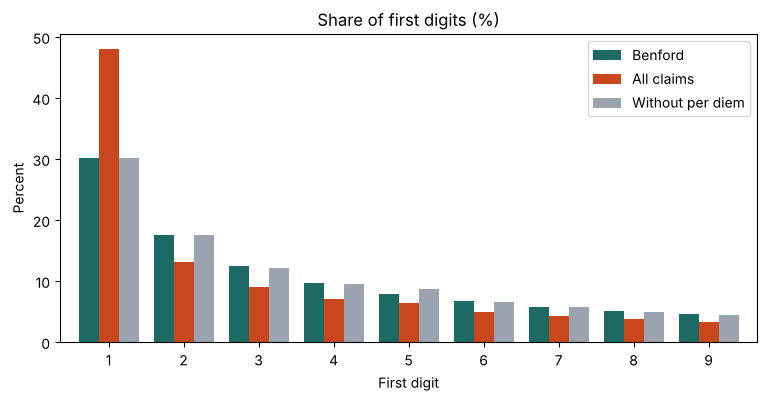

In [10]:
table = pd.DataFrame({"Benford": benford, "All claims": obs_all, "Without per diem": obs_x}) * 100
table.plot(kind="bar", figsize=(9, 4), color=["#1D6963", "#C8471C", "#9AA3AF"], width=0.8)
plt.title("Share of first digits (%)")
plt.xlabel("First digit")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()

### Task 4. MAD for each employee

Use the cleaned claims `x`. Rank employees by MAD and report the median.

In [11]:
counts = x.pivot_table(index="employee_id", columns="d1", values="amount", aggfunc="count", fill_value=0)
shares = counts.div(counts.sum(axis=1), axis=0)          # each employee's first-digit shares
emp_mad = (shares - benford).abs().mean(axis=1).sort_values(ascending=False)

print("Median MAD:", round(emp_mad.median(), 4))
print("Employees above 0.015:", (emp_mad > 0.015).sum(), "of", len(emp_mad))
emp_mad.head(6).round(4)

Median MAD: 0.0134
Employees above 0.015: 26 of 80


employee_id
E017    0.0812
E042    0.0461
E070    0.0305
E051    0.0273
E038    0.0269
E079    0.0228
dtype: float64

In [12]:
shares.loc[["E017", "E042", "E070"]].mul(100).round(1)

d1,1,2,3,4,5,6,7,8,9
employee_id,,,,,,,,,
E017,19.5,54.2,9.0,3.2,1.8,3.2,3.6,2.2,3.2
E042,12.6,15.9,12.0,8.6,10.3,11.0,11.3,10.3,8.0
E070,41.0,13.1,10.1,7.8,9.7,4.5,4.9,3.4,5.6


### Task 5. Claims just below and just above the ₹25,000 limit

In [13]:
x["below"] = x["amount"].between(20000, 24999.99)
x["above"] = x["amount"].between(25000, 29999.99)
band = x.groupby("employee_id")[["below", "above"]].sum()

others = band.drop(index="E017").sum()
print("Company, excluding E017: below =", others["below"], " above =", others["above"],
      " ratio =", round(others["below"] / others["above"], 2))
band.sort_values("below", ascending=False).head(5)

Company, excluding E017: below = 515  above = 332  ratio = 1.55


,below,above
employee_id,,
E017,126,2
E049,16,4
E010,13,11
E050,13,3
E046,11,4


### Task 6. Your memo

Write your audit memo in the handout: who you would refer, the evidence for each, one likely false positive, and two controls the AI agent needs.